In [ ]:
from pathlib import Path
import sys

for _parent in (Path.cwd(), *Path.cwd().parents):
    if (_parent / "src" / "regression_module.py").exists():
        sys.path.insert(0, str(_parent / "src"))
        break


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy, math
from logistic_module import load_data

In [2]:
X_train, y_train = load_data('student_admission.csv')

In [3]:
print(f"First 5 elements in X_train are:\n {X_train[:5]}")
print(f"Type of X_train: {type(X_train)}")

First 5 elements in X_train are:
 [[34.62365962 78.02469282]
 [30.28671077 43.89499752]
 [35.84740877 72.90219803]
 [60.18259939 86.3085521 ]
 [79.03273605 75.34437644]]
Type of X_train: <class 'numpy.ndarray'>


In [4]:
print(f"First 5 elements in y_train are:\n {y_train[:5]}")
print(f"Type of y_train: {type(y_train)}")

First 5 elements in y_train are:
 [0. 0. 0. 1. 1.]
Type of y_train: <class 'numpy.ndarray'>


In [5]:
print(f"The shape of X_train is: {X_train.shape}")
print(f"The shape of y_train is: {y_train.shape}")
print(f"We have m = {X_train.shape[0]} examples")

The shape of X_train is: (100, 2)
The shape of y_train is: (100,)
We have m = 100 examples


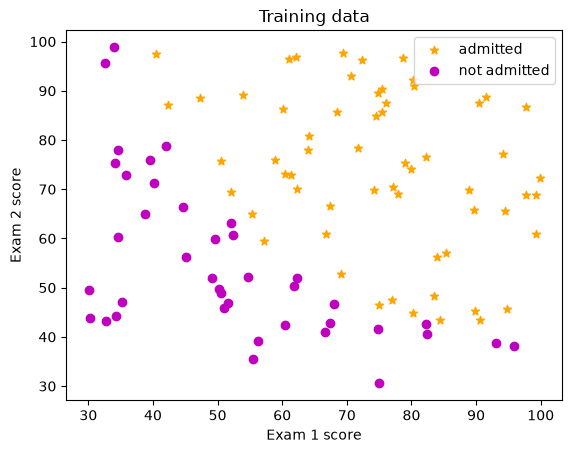

In [6]:
# visualize our data
positive = y_train == 1 # admitted students
negative = y_train == 0 # not admitted students

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='orange', marker='*', label='admitted')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='m', marker='o', label='not admitted')

plt.xlabel("Exam 1 score")
plt.ylabel("Exam 2 score")
plt.title("Training data")
plt.legend()
plt.show()

In [7]:
def sigmoid(z):
    g = 1 / (1 + np.exp(-z))
    return g

In [8]:
def compute_cost_logistic(X, y, w, b):
    m,n = X.shape
    cost = 0
    for i in range(m):
        z = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z)
        cost += -y[i] * np.log(f_wb_i) - (1-y[i]) * np.log(1-f_wb_i)
    cost /= m
    return cost

In [9]:
m,n = X_train.shape
w_init = np.zeros(n)
b_init = 0

cost_init = compute_cost_logistic(X_train, y_train, w_init, b_init)

print(f"Cost at inital parameters w, b (zeross): {cost_init:.3f}")

Cost at inital parameters w, b (zeross): 0.693


In [10]:
def compute_gradient_logistic(X, y, w, b):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        f_wb = sigmoid(np.dot(X[i], w) + b)
        err = f_wb - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i,j]
        dj_db += err
    dj_dw /= m
    dj_db /= m
    return dj_dw, dj_db

In [11]:
initial_w = np.zeros(n)
initial_b = 0.

dj_db, dj_dw = compute_gradient_logistic(X_train, y_train, initial_w, initial_b)
print(f'dj_db at initial w and b (zeros):{dj_db}' )
print(f'dj_dw at initial w and b (zeros):{dj_dw.tolist()}' )

dj_db at initial w and b (zeros):[-12.00921659 -11.26284221]
dj_dw at initial w and b (zeros):-0.1


In [12]:
def gradient_descent_logistic(X, y, w, b, alpha, num_iters):

    hist = {}
    hist['cost'] = []
    hist['parameters'] = []
    hist['gradients'] = []
    hist['iteration'] = []
        
    for i in range(num_iters):
        
        dj_dw, dj_db = compute_gradient_logistic(X, y, w, b)
        
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:
            hist['cost'].append(compute_cost_logistic(X, y, w, b))
            hist['parameters'].append((w, b))
            hist['gradients'].append((dj_dw, dj_db))
            hist['iteration'].append(i)
        if i % math.ceil(num_iters / 10) == 0:
            print(
                f"Iteration: {i:5}, Cost: {hist['cost'][-1]:8.3f}"
            )
    return w, b, hist

In [13]:
w_in = np.zeros(X_train.shape[1])
b_in = 0
alpha = 0.001
iterations = 120000

w_out, b_out, hist = gradient_descent_logistic(X_train, y_train, w_in, b_in, alpha, iterations)

Iteration:     0, Cost:    0.698
Iteration: 12000, Cost:    0.577
Iteration: 24000, Cost:    0.534
Iteration: 36000, Cost:    0.499
Iteration: 48000, Cost:    0.469
Iteration: 60000, Cost:    0.445
Iteration: 72000, Cost:    0.425
Iteration: 84000, Cost:    0.407
Iteration: 96000, Cost:    0.392
Iteration: 108000, Cost:    0.387


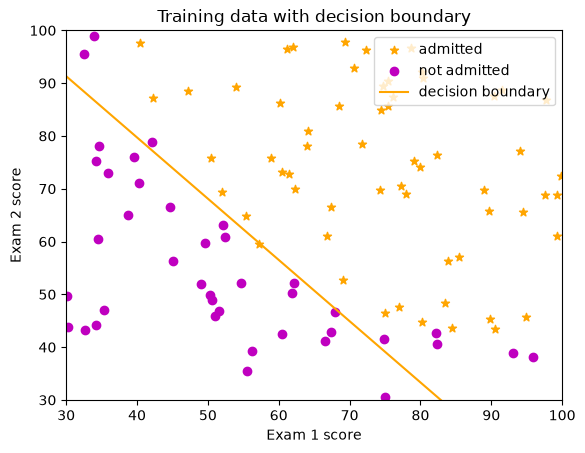

In [14]:
# also plot decision boundary with the computed parameters
# with threshold of 0.5 decision boundary would be w0*x0 + w1*x1 + b = 0
x0 = -b_out / w_out[0]
x1 = -b_out / w_out[1]

# (x0, 0) , (0, x1)

positive = y_train == 1 # admitted students
negative = y_train == 0 # not admitted students

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='orange', marker='*', label='admitted')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='m', marker='o', label='not admitted')

plt.plot([x0, 0], [0, x1], c='orange', label='decision boundary')

plt.xlabel("Exam 1 score")
plt.ylabel("Exam 2 score")
plt.title("Training data with decision boundary")
plt.axis([30,100,30,100])
plt.legend(loc='upper right')
plt.show()


In [18]:
def predict(X, w, b):
    m,n = X.shape
    p = np.zeros(m)
    for i in range(m):
        p[i] = sigmoid(np.dot(X[i], w) + b)
        p[i] = 1 if p[i] >= 0.5 else 0
    return p

In [19]:
np.random.seed(1)
tmp_w = np.random.randn(2)
tmp_b = 0.3    
tmp_X = np.random.randn(4, 2) - 0.5

tmp_p = predict(tmp_X, tmp_w, tmp_b)
print(f'Output of predict: shape {tmp_p.shape}, value {tmp_p}')

Output of predict: shape (4,), value [0. 1. 1. 1.]


In [21]:
#model accuracy
p = predict(X_train, w_out, b_out)
print(f"Train accuracy: {np.mean(p==y_train)*100}")

Train accuracy: 91.0
